# Mice Protein Expression: Unsupervised Clustering & PCA

**Objective:** Apply dimensionality reduction (PCA) and unsupervised clustering (K-Means) to identify underlying patterns in protein expression data.

In [33]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "scripts"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

from data_pipeline import prepare_eda_data

# Plot settings
sns.set_theme(style='whitegrid', palette='pastel', font_scale=1.2)
    
# Load the processed data generated by scripts/preprocessing.py
processed_path = '../data/processed/mice_protein_processed.csv'
try:
    df = pd.read_csv(processed_path)
except FileNotFoundError:
    df = prepare_eda_data(save=True)  # Call the preprocessing function to generate the processed data

# Separate features and labels
protein_cols = [col for col in df.columns if col not in ['class_encoded', 'class_name']]
X_normalized_df = df[protein_cols]
y = df['class_encoded'].values
y_raw = df['class_name'].values

print(f"Loaded processed data. Feature matrix shape: {X_normalized_df.shape}")

Loaded processed data. Feature matrix shape: (1080, 77)


## 1. Principal Component Analysis (PCA)
We reduce the dimensionality to 2 components to visualize the separation of the true biological classes in a 2D space.

PC1 explained variance ratio: 0.2535
PC2 explained variance ratio: 0.1691
Total explained variance: 0.4226


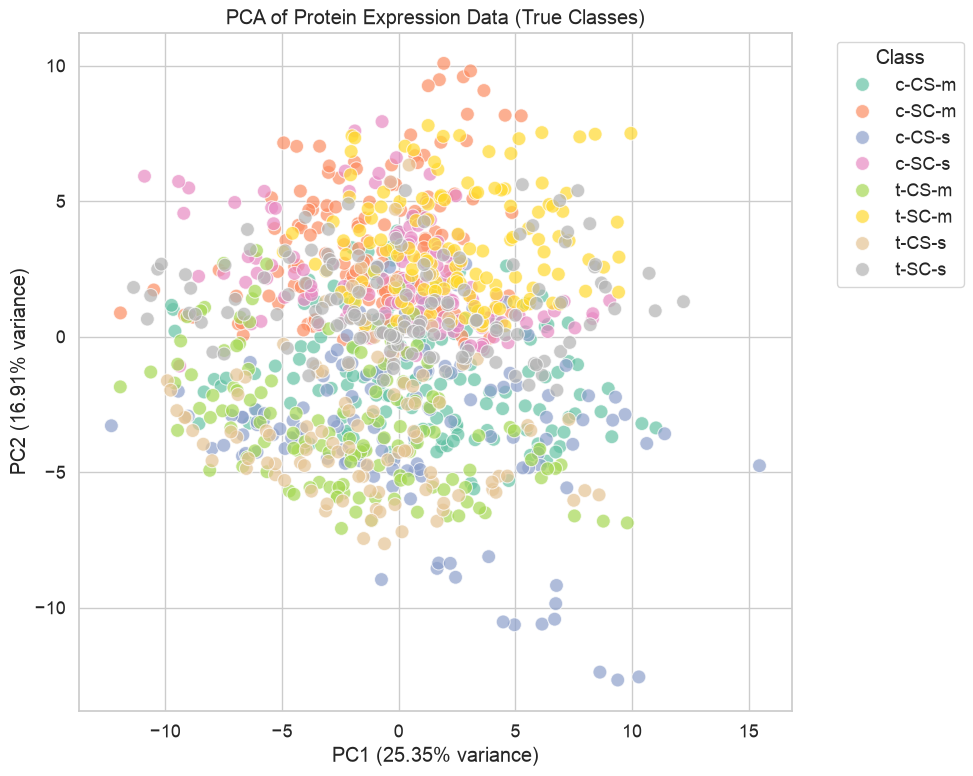

In [18]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_normalized_df)

X_pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'], index=X_normalized_df.index)
X_pca_df["class"] = y_raw

evr = pca.explained_variance_ratio_

print(f"PC1 explained variance ratio: {evr[0]:.4f}")
print(f"PC2 explained variance ratio: {evr[1]:.4f}")
print(f"Total explained variance: {evr.sum():.4f}")

plt.figure(figsize=(10, 8))
sns.scatterplot(x='PC1', y='PC2', hue='class', data=X_pca_df, palette='Set2', s=100, alpha=0.7)
plt.title('PCA of Protein Expression Data (True Classes)')
plt.xlabel(f'PC1 ({evr[0]*100:.2f}% variance)')
plt.ylabel(f'PC2 ({evr[1]*100:.2f}% variance)')
plt.legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 2. K-Means Clustering
We apply K-Means with $K=8$ (matching the number of true biological classes) to see if the algorithm can naturally discover the underlying groups without using the labels.

In [19]:
K = 8 # Match the number of true classes
kmeans = KMeans(n_clusters=K, random_state=42, n_init='auto')

cluster_labels = kmeans.fit_predict(X_normalized_df)
X_pca_df["cluster"] = cluster_labels.astype(str)

# Metrics
silhouette_avg = silhouette_score(X_normalized_df, cluster_labels)
silhouette_samples_values = silhouette_samples(X_normalized_df, cluster_labels)

print(f"Silhouette Score for K={K}: {silhouette_avg:.4f}")
print(f"Inertia (Sum of squared distances): {kmeans.inertia_:.4f}")
print(f"\nCluster sizes:\n{pd.Series(cluster_labels).value_counts().sort_index()}")

Silhouette Score for K=8: 0.1225
Inertia (Sum of squared distances): 48173.4558

Cluster sizes:
0    145
1    222
2    160
3    168
4    165
5    117
6     15
7     88
Name: count, dtype: int64


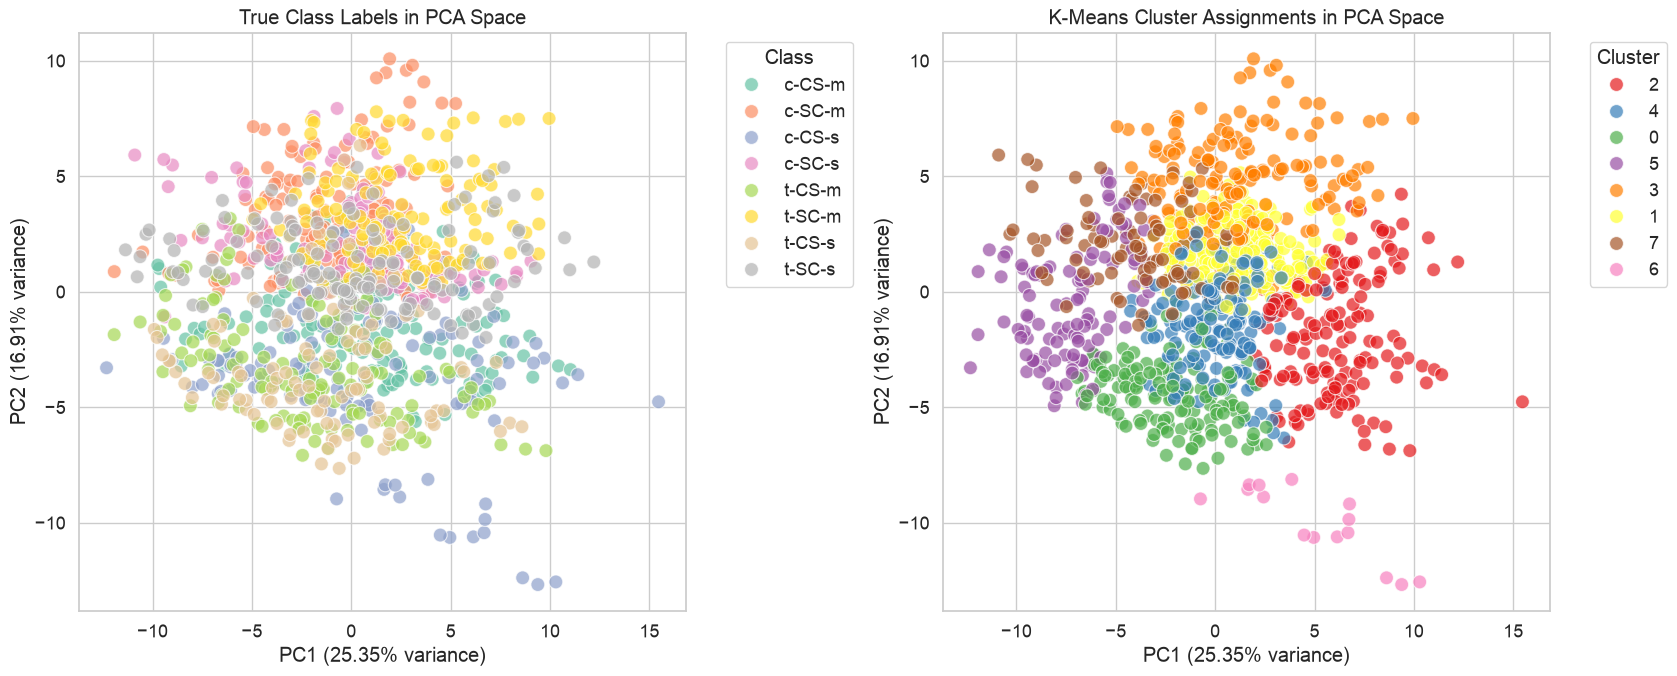

In [20]:
# Visual Comparison: True Labels vs. K-Means Assignments
fig, ax = plt.subplots(1, 2, figsize=(17, 7))

# True classes
sns.scatterplot(x='PC1', y='PC2', hue='class', data=X_pca_df, palette='Set2', s=100, alpha=0.7, ax=ax[0])
ax[0].set_title('True Class Labels in PCA Space')
ax[0].set_xlabel(f'PC1 ({evr[0]*100:.2f}% variance)')
ax[0].set_ylabel(f'PC2 ({evr[1]*100:.2f}% variance)')
ax[0].legend(title='Class', bbox_to_anchor=(1.05, 1), loc='upper left')

# K-Means clusters
sns.scatterplot(x='PC1', y='PC2', hue='cluster', data=X_pca_df, palette='Set1', s=100, alpha=0.7, ax=ax[1])
ax[1].set_title('K-Means Cluster Assignments in PCA Space')
ax[1].set_xlabel(f'PC1 ({evr[0]*100:.2f}% variance)')
ax[1].set_ylabel(f'PC2 ({evr[1]*100:.2f}% variance)')
ax[1].legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 3. Clustering Evaluation
We evaluate the quality of the clusters using Silhouette analysis and by cross-tabulating the unsupervised clusters against the true biological classes.

Average silhouette score by true class:
class
c-CS-s    0.162495
c-SC-m    0.139683
t-CS-m    0.139067
c-SC-s    0.135301
t-SC-m    0.108631
t-CS-s    0.108083
c-CS-m    0.096067
t-SC-s    0.088716
Name: Silhouette, dtype: float64

Average silhouette score by cluster:
Cluster
6    0.488034
1    0.210418
4    0.124708
5    0.121659
7    0.119772
2    0.119463
0    0.105563
3   -0.008783
Name: Silhouette, dtype: float64

Cross-tabulation of true class labels and K-Means cluster assignments:
Cluster   0   1   2   3   4   5   6   7
class                                  
c-CS-m   16  10  54  19  34  17   0   0
c-CS-s   42   0  25   6  35  12  15   0
c-SC-m    0  77   0  43   0  20   0  10
c-SC-s    0  71  12  22   0  10   0  20
t-CS-m   37   0  13   0  49  36   0   0
t-CS-s   48   0  13   7  23  12   0   2
t-SC-m    0  59  12  51   0   3   0  10
t-SC-s    2   5  31  20  24   7   0  46


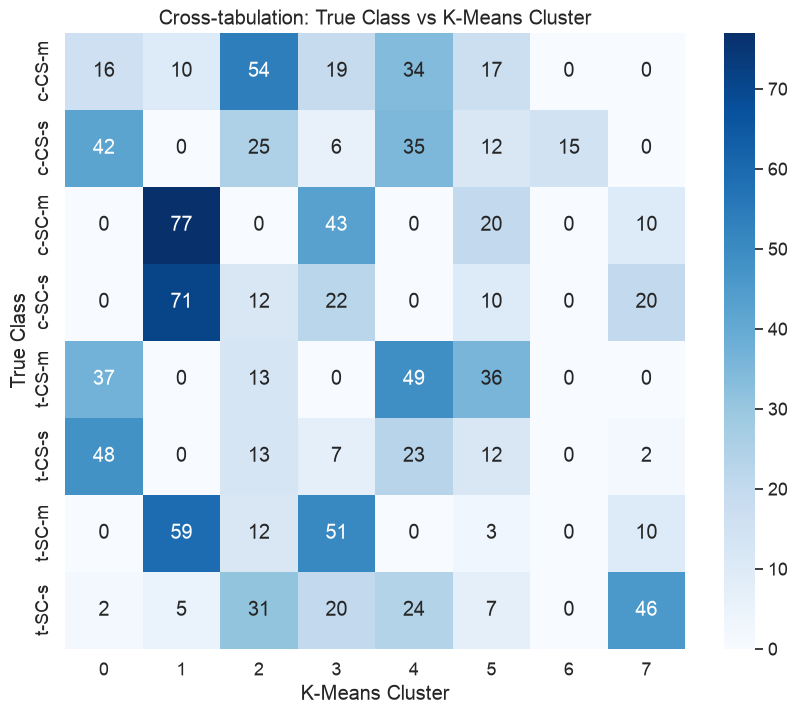

In [21]:
silhouette_summary = pd.DataFrame({
    "class": y_raw,
    'Cluster': cluster_labels.astype(str),
    "Silhouette": silhouette_samples_values
})

print("Average silhouette score by true class:")
print(silhouette_summary.groupby("class")["Silhouette"].mean().sort_values(ascending=False))

print("\nAverage silhouette score by cluster:")
print(silhouette_summary.groupby("Cluster")["Silhouette"].mean().sort_values(ascending=False))

print("\nCross-tabulation of true class labels and K-Means cluster assignments:")
crosstab = pd.crosstab(silhouette_summary["class"], silhouette_summary["Cluster"])
print(crosstab)

# Heatmap visualization of the crosstab
plt.figure(figsize=(10, 8))
sns.heatmap(crosstab, annot=True, fmt='d', cmap='Blues')
plt.title('Cross-tabulation: True Class vs K-Means Cluster')
plt.xlabel('K-Means Cluster')
plt.ylabel('True Class')
plt.show()

## 4. Discussion & Conclusion

From the cross-tabulation and PCA visualizations, unsupervised clustering (K-Means) reveals that the dominant protein expression patterns are heavily driven by **Behavior** (e.g., CS, SC) and **Genotype** (c, t). 

The pharmacological treatment (saline vs. cocaine) appears too subtle to be captured by K-Means as a primary grouping factor in the global protein expression space. This suggests that while baseline genetics and resulting behavioral phenotypes dictate the largest variances in protein expression, the acute chemical treatment induces more localized or subtle changes that require supervised learning or more granular feature selection to detect accurately.